# The transcriptome and the spatial repertoire

Spatial receptor data come with a spot-level transcriptome, and most questions about receptors are asked *by region*:
is the repertoire of a germinal centre more clonal than that of the plasma-cell area, do two regions share clones, do
T cells avoid the GC border? This notebook covers both halves on one AIR-SPACE lymph node (day 21 after vaccinia
infection, GEO GSE286452):

* **Part A, the transcriptome**: QC, filtering, normalisation, clustering, cell types, germinal centres and the
  plasma-cell area, pseudobulk differential expression with GCs as replicates, neighbourhood enrichment. These are thin
  wrappers of scanpy with spatial defaults.
* **Part B, the repertoire**: clonal expansion, diversity, overlap and gene usage by region, clonotype networks,
  per-clone spatial dispersion, public clonotypes across the six AIR-SPACE mice, and a niche profile along the distance
  to the GC border.

Two rules run through Part B. Clones are counted in **units** (by default *loci*: same-clone molecules within 15 µm
merged, about one cell), not molecules. And regions hold different numbers of units, so every comparison is either
**rarefied** to a common size or tested against a **placebo** that shows what random placement of the tissue's intact
clones gives at the observed sizes.

In [1]:
import time

t_start = time.time()

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import spaclone
from spaclone import gex, io, pl, pp, tl

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 50)
plt.rcParams["figure.dpi"] = 100
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"  # one-line warnings
print("spaclone", spaclone.__version__)

spaclone 1.0.0


## The data

`spaclone.datasets.airspace("D21")` downloads the D21 bead counts and clone table from GEO once (about 78 MB,
verified by sha256; needs `pip install "spaclone[datasets]"`) into the user cache, or into the folder in the
environment variable `SPACLONE_DATA_DIR`. The public-clonotype section reads all six nodes of the series (Mock, D3,
D7, D10, D14 and D21, about 550 MB in all), which are built in the same way.

In [2]:
h5ad, clone_table = spaclone.datasets.airspace("D21")
sa = io.read_airspace(h5ad, clone_table)
G = sa.gex
G

AnnData object with n_obs × n_vars = 79423 × 31053
    obs: 'barcode', 'x', 'y', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'x_src', 'y_src', 'in_tissue', 'library_id'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'spaclone'
    obsm: 'spatial'
    layers: None (.X)

# Part A: the transcriptome

## QC and filtering

The bead array covers more than the tissue section. `gex.qc_metrics` adds scanpy's per-unit metrics to `obs` and
summarises them on and off the tissue (the reader called tissue beads with the authors' rule: ≥ 100 counts and ≥ 15
such beads within 100 µm).

In [3]:
gex.qc_metrics(G)

,library,tissue,n_units,median_counts,median_genes,median_pct_mt,total_counts,share_of_counts
0,all,in_tissue,23040,340.0,250.0,1.67364,10349861.0,0.952457
1,all,off_tissue,56383,0.0,0.0,0.00000,516620.0,0.047543


95% of the counts are on the 23,040 tissue beads; the 56,383 off-tissue beads have a median of 0 counts. `gex.filter`
applies thresholds and, with `off_tissue="drop"`, removes the off-tissue units explicitly (the default `"keep"` never
drops them silently, because off-tissue units are the reference of several trust tests).

In [4]:
T = gex.filter(G, min_counts=100, off_tissue="drop")
print(G.shape, "->", T.shape)

(79423, 31053) -> (23040, 31053)


## Normalisation, highly variable genes, PCA and clustering

`gex.preprocess` keeps the raw counts in `layers["counts"]`, normalises to 10,000 counts per bead, log-transforms,
selects 2,000 highly variable genes and runs PCA. Ig, TCR, mitochondrial, ribosomal and haemoglobin genes cannot be
highly variable genes by default: Ig genes would otherwise drive the clustering by plasma-cell RNA spilling over to
neighbouring beads. `gex.cluster` runs Leiden on the neighbour graph, seeded.

In [5]:
hvg = gex.preprocess(T, n_hvg=2000, n_pcs=30, rng=0)
clusters = gex.cluster(T, resolution=0.8, rng=0)
print(int(T.var["highly_variable"].sum()), "highly variable genes;", len(clusters), "clusters")
clusters.T

2000 highly variable genes; 10 clusters


,0,1,2,3,4,5,6,7,8,9
cluster,0,1,2,3,4,5,6,7,8,9
n_units,3460,2377,2925,1644,3979,1374,4960,1497,800,24


## Cell types and regions

`gex.score_cell_types` types every bead by the marker module it is most enriched for (built-in mouse immune modules);
beads with fewer than two marker counts stay unassigned, which is common for 10 µm beads with a few hundred counts.

In [6]:
gex.score_cell_types(T, markers="immune_mouse")[["cell_type", "genes_used", "n_units", "pct_units"]]

,cell_type,genes_used,n_units,pct_units
0,B,"Cd79a,Cd79b,Ms4a1,Cd19,Pax5,Cr2,Fcer2a",4561,19.796007
1,GC_B,"Aicda,S1pr2,Gcsam,Rgs13,Mef2b",946,4.105903
2,ASC,"Jchain,Xbp1,Prdm1,Sdc1,Mzb1",1405,6.098090
3,T,"Cd3e,Cd3d,Cd3g,Cd4,Cd8a,Cd8b1",1070,4.644097
4,Tfh,"Il21,Pdcd1,Icos,Tox2,Ascl2,Sh2d1a",87,0.377604
5,myeloid,"Lyz2,Cd68,C1qa,C1qb,Csf1r",1642,7.126736
6,stromal,"Col1a1,Col3a1,Pdpn,Ccl21a,Pecam1,Cdh5",835,3.624132
7,erythroid,"Hba-a1,Hba-a2,Hbb-bs,Hbb-bt,Alas2,Gypa",49,0.212674
8,unassigned,,12445,54.014757


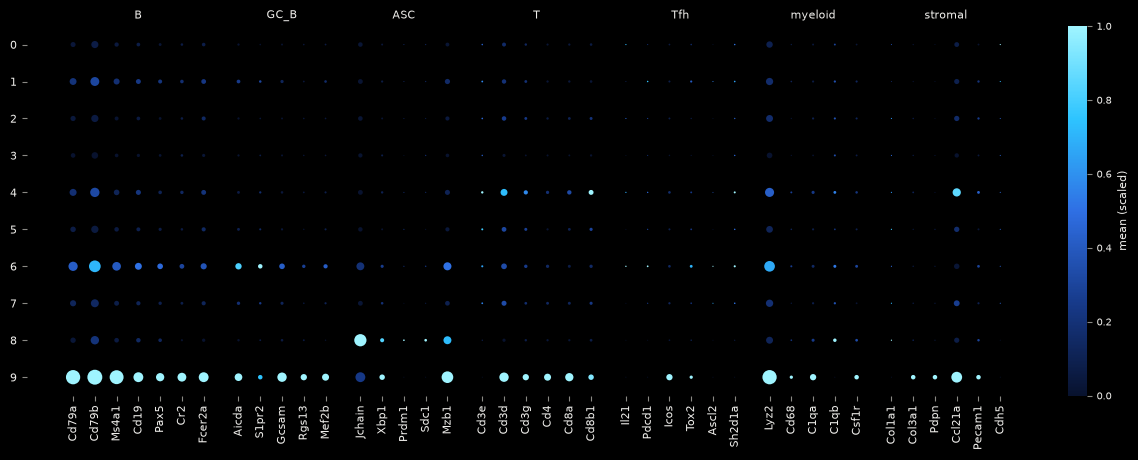

In [7]:
markers = {k: v for k, v in gex.MARKERS["immune_mouse"].items() if k != "erythroid"}
fig, ax = plt.subplots(figsize=(14, 4.8))
pl.gex_dotplot(T, markers, groupby="leiden", ax=ax)
plt.show()

Most clusters split beads by depth rather than by type (a 10 µm bead mixes cells), but one cluster carries the B and
GC B markers (Cd79a/b, Ms4a1, Aicda, S1pr2, Gcsam), one the plasma-cell markers (Jchain, Xbp1, Mzb1) and one the T-zone
markers (Cd3, Ccl21a); a small cluster of very deep beads has every marker. The marker-module types above are the
labels we use below.

Germinal centres are called from the GC B-cell marker share (top 8% of beads within 30 µm, DBSCAN 25 µm, ≥ 30 beads,
widened 25 µm) and the plasma-cell area from the plasma-cell marker share. Each GC is an *instance* with its own id,
which part B and the differential expression use as replicates.

{'other': 19240, 'GC': 1987, 'ASC': 1813}


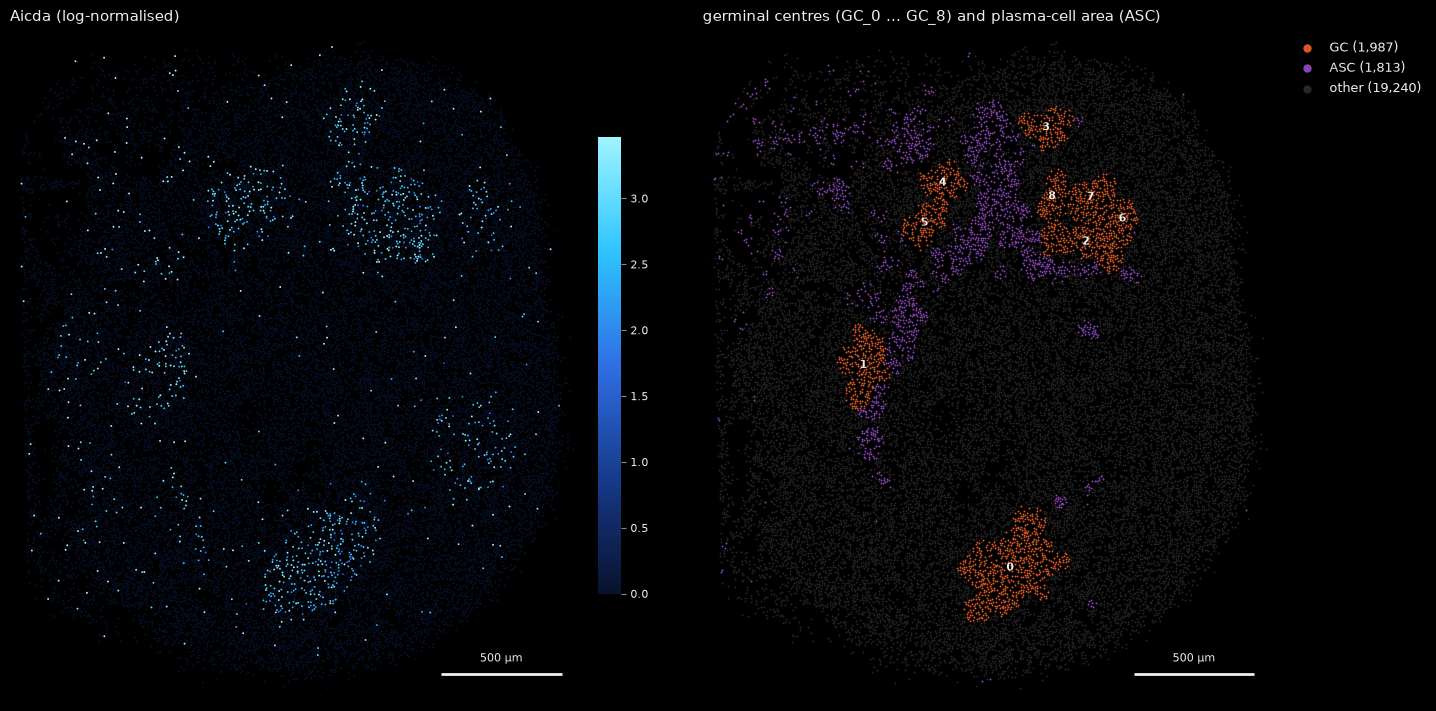

In [8]:
gcs = gex.call_regions(T, kind="germinal_centre")
gex.call_regions(T, kind="plasma_cell")
print(T.obs["region"].value_counts().to_dict())
fig, axes = plt.subplots(1, 2, figsize=(15, 7), layout="constrained")
pl.gex_map(T, "Aicda", ax=axes[0], title="Aicda (log-normalised)")
pl.gex_regions(T, ax=axes[1], title="germinal centres (GC_0 ... GC_8) and plasma-cell area (ASC)")
plt.show()

## Which genes differ in germinal centres? Pseudobulk with GCs as replicates

Beads of one GC are not independent replicates: a test with beads as replicates (scanpy's Wilcoxon) calls thousands
of genes because it counts the same germinal centre many times. `gex.rank_genes_regions` sums the counts of each GC
into one pseudobulk sample and compares the nine GCs with the rest of the tissue, cut into 200 µm tiles that act as
the reference replicates (limma moderated t on TMM log-CPM).

In [9]:
de = gex.rank_genes_regions(T, region_key="region", instance_key="region_id", groups="GC", reference="rest")
print(de)
de.table.head(12)[["gene", "log2fc", "logcpm_group", "logcpm_reference", "p_value", "q_value"]]

TestResult(rank_genes_regions: n_instances[GC]=9, n_genes[GC]=1349, n_q05[GC]=168; table 1349×12)


,gene,log2fc,logcpm_group,logcpm_reference,p_value,q_value
0,Ighd,-1.762134,8.671953,10.434087,2.350024e-11,3.170182e-08
1,Malat1,-1.600020,8.564586,10.164606,2.031021e-10,1.369924e-07
2,Gcsam,2.248290,8.753952,6.505662,3.392356e-10,1.525430e-07
3,Aicda,2.307534,9.066132,6.758598,6.708660e-10,2.262496e-07
4,Pou2af1,1.755804,10.568477,8.812673,5.925255e-09,1.598634e-06
5,Tuba1b,1.012856,11.955256,10.942400,9.893083e-08,1.945262e-05
6,Hmces,1.825695,8.900651,7.074955,1.009402e-07,1.945262e-05
7,Dhfr,1.714386,8.368589,6.654203,1.332257e-07,2.246519e-05
8,Nuggc,1.784030,8.231270,6.447239,1.717532e-07,2.574389e-05
9,Sub1,-1.360617,8.027541,9.388158,2.277715e-07,2.863362e-05


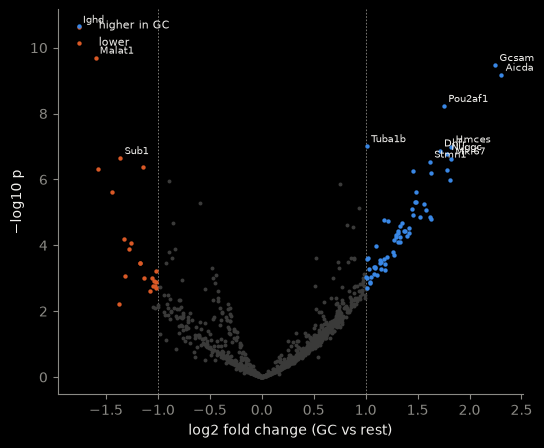

In [10]:
ax = pl.gex_volcano(de, group="GC", label_top=12)
plt.show()

168 genes differ at q < 0.05. The top ones are the GC programme (Aicda, Gcsam, Nuggc, Pou2af1, Hmces, and Mki67, Stmn1,
Tuba1b and Dhfr of the cycling dark-zone cells), while Ighd and Malat1 are lower in GCs, as expected from the naive
follicular B cells around them. Aicda and Gcsam are among the markers that *defined* the GCs, so their own differences
are circular; the informative genes are the ones not used for calling (Pou2af1, Hmces, Nuggc, Mki67, Stmn1, ...).

## Neighbourhood enrichment

`gex.nhood_enrichment` counts bead pairs within 25 µm by class and compares them with class labels permuted among the
beads (squidpy's statistic, with Monte-Carlo p-values and BH q-values). Every class is enriched with itself because
regions are contiguous; the pairs of different classes are the informative ones.

In [11]:
ne = gex.nhood_enrichment(T, cluster_key="cell_type", radius_um=25, n_perm=200, rng=0)
pairs = ne.table[(ne.table.cluster_a != ne.table.cluster_b) & ~ne.table.cluster_a.eq("unassigned")
                 & ~ne.table.cluster_b.eq("unassigned")]
pairs.sort_values("z", ascending=False)[["cluster_a", "cluster_b", "statistic", "null_mean", "ratio", "z", "q_value"]].head(10)

,cluster_a,cluster_b,statistic,null_mean,ratio,z,q_value
13,GC_B,myeloid,1102.0,608.960,1.809643,19.983715,0.013993
10,GC_B,ASC,848.0,516.345,1.642313,15.261987,0.013993
1,B,GC_B,2285.0,1682.075,1.358441,14.312653,0.013993
27,T,stromal,623.0,350.435,1.777790,13.341606,0.013993
4,B,Tfh,212.0,153.555,1.380613,4.812048,0.013993
5,B,myeloid,3139.0,2926.680,1.072546,4.213100,0.013993
40,stromal,erythroid,28.0,16.275,1.720430,3.183227,0.013993
12,GC_B,Tfh,49.0,31.710,1.545254,3.120032,0.013993
20,ASC,myeloid,986.0,898.020,1.097971,3.025229,0.026339
22,ASC,erythroid,42.0,27.085,1.550674,2.805221,0.026339


GC B beads neighbour myeloid beads 1.8 times (tingible-body macrophages clear apoptotic GC B cells), plasma-cell
(ASC) beads 1.6 times and B beads 1.4 times more often than random labelling, and T beads sit next to stromal beads
(the T-zone reticular network, Ccl21a): the expected anatomy of a reactive lymph node.

# Part B: the spatial repertoire

We keep receptor molecules on tissue with a valid junction and give each the region of its bead. Most of Part B uses
the heavy chain (IGH), the clonal marker of a B cell.

In [12]:
air = pp.filter_records(sa.air, on_tissue=True).air.reset_index(drop=True)
air["region"] = air["spot_id"].map(T.obs["region"].astype(str)).fillna("other").to_numpy()
igh = air[air["locus"] == "IGH"].reset_index(drop=True)
print(air["locus"].value_counts().to_dict())
pd.crosstab(igh["region"], igh["locus"], margins=True)

{'IGK': 9127, 'IGH': 2542, 'IGL': 1246, 'TRB': 696, 'TRA': 226}


locus,IGH,All
region,,
ASC,999,999
GC,191,191
other,1352,1352
All,2542,2542


## Clonal expansion by region

`tl.clonal_expansion` classifies every locus by the size of its clone (1, 2, 3–5, 6–20, > 20 loci) and gives each
region's share of loci (and of clones) in each class.

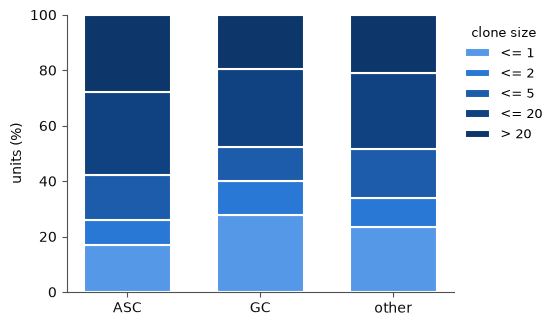

expansion,<= 1,<= 2,<= 5,<= 20,> 20
region,,,,,
ASC,0.171,0.088,0.164,0.297,0.279
GC,0.279,0.121,0.121,0.285,0.194
other,0.233,0.107,0.174,0.277,0.210


In [13]:
ce = tl.clonal_expansion(igh, by="region")
ax = pl.clonal_expansion(ce)
plt.show()
ce.pivot_table(index="region", columns="expansion", values="share_units").round(3)

## Diversity, rarefied and against a placebo

Richness, Gini and the expanded share all move with the number of units, and the GCs hold 165 IGH loci against 848 in
the plasma-cell area. `tl.diversity` therefore rarefies every region to the smallest region's size (200 draws) and,
with `placebo="clones"`, re-computes everything on random placements of the section's intact clones: every clone keeps
its footprint (the offsets of its loci from its centroid) and moves to the centroid of another clone, and its loci take
the region found at their new place. The regions stay as they are and the clones stay whole, so the placebo asks
whether a region holds larger or smaller clones than random placement of the tissue's clones gives; a difference the
placebo reproduces is built into the regions' sizes. (Permuting clone labels among loci, `placebo="labels"`, would
instead test whether the loci of a clone are scattered at random, which clustered clones never are; the package warns
when it is used.)

In [14]:
dv = tl.diversity(igh, by="region", metrics=("richness", "shannon", "gini", "expanded"), placebo="clones",
                  n_perm=200, rng=0)
print(dv)
dv.table.query("kind == 'group'")[["group", "metric", "n_units", "value", "rarefied", "null_mean", "p_value", "q_value"]].round(3)

TestResult(diversity: groups=3, rarefied_to=165, n_perm=200, contrast=ASC - GC (richness), difference=-13.06, p_value=0.00995; table 24×24)


,group,metric,n_units,value,rarefied,null_mean,p_value,q_value
0,ASC,richness,848.0,367.000,114.935,143.086,0.020,0.040
1,ASC,shannon,848.0,5.386,4.573,4.821,0.010,0.024
2,ASC,gini,848.0,0.475,0.255,0.199,0.010,0.024
3,ASC,expanded,848.0,0.711,0.465,0.346,0.010,0.024
4,GC,richness,165.0,128.000,128.000,129.360,0.945,0.945
5,GC,shannon,165.0,4.720,4.720,4.668,0.587,0.783
6,GC,gini,165.0,0.198,0.198,0.256,0.060,0.102
7,GC,expanded,165.0,0.358,0.358,0.443,0.090,0.134
8,other,richness,1226.0,554.000,127.810,132.190,0.667,0.800
9,other,shannon,1226.0,5.847,4.740,4.732,0.846,0.923


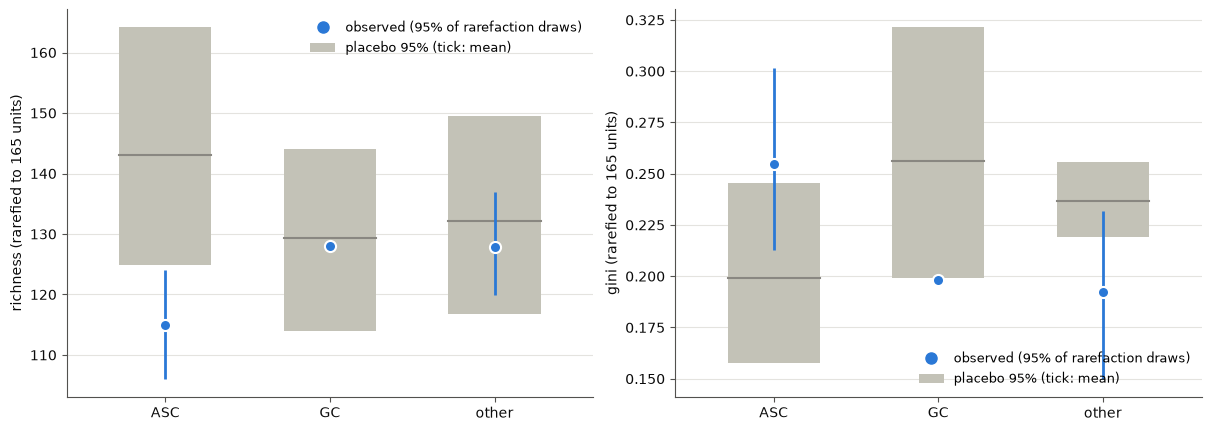

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
pl.diversity(dv, metric="richness", ax=axes[0])
pl.diversity(dv, metric="gini", ax=axes[1])
plt.show()

Rarefied to 165 loci, the plasma-cell area holds fewer clones than random placement of intact clones gives (richness
115 against 143, q = 0.04), with a higher Gini coefficient (0.26 against 0.20) and more loci in expanded clones (0.47
against 0.35): expanded clones sit in the plasma-cell area more often than chance would place them there. The rest of
the node is the mirror image (Gini 0.19 against 0.24, q = 0.02), and the GCs stay within their placebo range
(q ≥ 0.10). The raw Gini values (0.48 in the plasma-cell area, 0.20 in the GCs) would have suggested a much larger
contrast; most of it is the number of loci.

## Overlap between regions

`tl.overlap` computes the Morisita–Horn overlap of clone frequencies for every pair of regions, against the same
placebo (intact clones placed at random, regions fixed).

In [16]:
ov = tl.overlap(igh, by="region", placebo="clones", n_perm=200, rng=0)
ov.table[["group_a", "group_b", "shared_clones", "statistic", "null_mean", "p_value", "q_value"]].round(3)

,group_a,group_b,shared_clones,statistic,null_mean,p_value,q_value
0,ASC,GC,66,0.528,0.429,0.199,0.299
1,ASC,other,195,0.787,0.563,0.010,0.030
2,GC,other,72,0.514,0.509,0.965,0.965


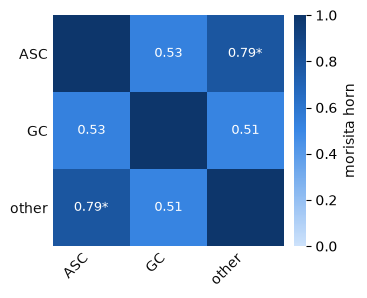

In [17]:
ax = pl.overlap(ov)
plt.show()

Every pair of regions shares clones (66 between the plasma-cell area and the GCs). The plasma-cell area overlaps with
the rest of the node more than random placement of intact clones gives (0.79 against 0.56, q = 0.03): its expanded
clones also have members outside it. The GC pairs are within the placebo range.

## V gene usage

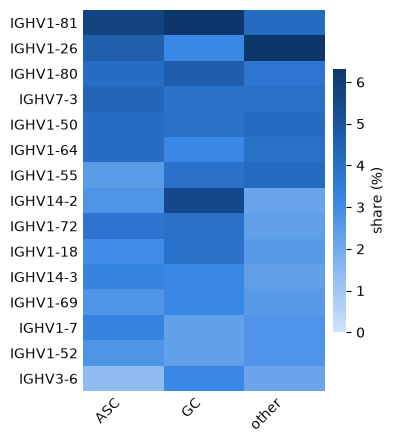

In [18]:
gu = tl.gene_usage(igh, by="region", gene="v_call")
ax = pl.gene_usage(gu, top=15)
plt.show()

`tl.gene_usage` counts clones by default (`weight="clones"`), so one large clone does not dominate a region's usage.
Usage is broadly similar across regions; with a few hundred clones per region, single-gene differences need a test
(e.g. the overlap or diversity placebos above applied to a gene column) before being read.

## Clonotype networks

`tl.clonotype_network` links clonotypes whose junctions differ by at most one amino acid (same V and J), as scirpy
does, and summarises each connected component in space: its loci, sections, centroid, radius of gyration and minimum
spanning tree length.

In [19]:
net = tl.clonotype_network(igh, cutoff=1, region_key="region")
comp = net.components.sort_values(["n_nodes", "n_units"], ascending=False)
print(f"{len(net.nodes):,} nodes, {len(net.edges):,} edges, {(net.components.n_nodes > 1).sum()} components with > 1 node")
comp.head(8)[["component", "n_nodes", "n_units", "v_gene", "j_gene", "n_clones", "rg_um", "regions", "main_region_share"]]

840 nodes, 127 edges, 84 components with > 1 node


,component,n_nodes,n_units,v_gene,j_gene,n_clones,rg_um,regions,main_region_share
640,640,5,40,IGHV7-3,IGHJ1,2,835.650127,ASC;GC;other,0.500000
499,499,5,33,IGHV14-2,IGHJ1,3,610.379582,ASC;GC;other,0.515152
376,376,5,31,IGHV1-76,IGHJ4,2,667.530794,ASC;other,0.677419
540,540,5,30,IGHV2-2,IGHJ2,1,767.191507,ASC;other,0.633333
661,661,4,52,IGHV7-3,IGHJ4,1,710.215116,ASC;GC;other,0.442308
646,646,4,25,IGHV7-3,IGHJ1,1,673.817288,ASC;GC;other,0.560000
412,412,4,20,IGHV1-80,IGHJ4,1,749.277726,ASC;GC;other,0.450000
576,576,4,17,IGHV3-6,IGHJ4,3,682.043175,ASC;GC;other,0.705882


A component is not a clone: single linkage chains similar junctions, and short junctions are shared by unrelated
cells. The largest components here join 4–5 junction variants of one or a few MiXCR clones; their members are spread
over the node (radius of gyration 600–850 µm), which is the question the next test asks properly.

## Are clones spatially clustered? Per-clone dispersion

`tl.clone_dispersion` tests every clone with at least 5 loci: is the mean nearest-neighbour distance (and the minimum
spanning tree) of its loci shorter than for the same number of loci drawn at random from all IGH loci of the section?
p-values come from sequential Monte-Carlo sampling (draws are added until each clone has 10 exceedances, or up to the
number that would let one clone pass BH), and q-values from BH over the clones.

In [20]:
disp = tl.clone_dispersion(igh, min_units=5, n_perm=200, rng=0)
print(disp)
disp.table.query("measure == 'mst'").sort_values("p_value").head(8)[
    ["clone_id", "n_units", "statistic", "null_mean", "ratio", "p_value", "q_value", "n_perm"]].round(4)

TestResult(clone_dispersion: clones_tested=106, significant=0, measure=mean_nn, alpha=0.05, p_method=mc/sequential, max_perm=2120; table 212×18)


,clone_id,n_units,statistic,null_mean,ratio,p_value,q_value,n_perm
207,80,26,4012.9578,6516.8341,0.6158,0.0005,0.0500,2120
211,96,22,4207.0140,5998.2999,0.7014,0.0014,0.0666,2120
199,62,27,4701.4531,6679.3720,0.7039,0.0019,0.0666,2120
1,109,23,4356.8867,6116.6950,0.7123,0.0042,0.1003,2120
7,119,18,3712.1534,5404.6591,0.6868,0.0056,0.1003,1799
153,42,46,7122.3207,8706.6081,0.8180,0.0057,0.1003,1762
47,202,14,3195.9719,4728.1806,0.6759,0.0113,0.1499,884
85,299,8,1897.0831,3409.9567,0.5563,0.0113,0.1499,884


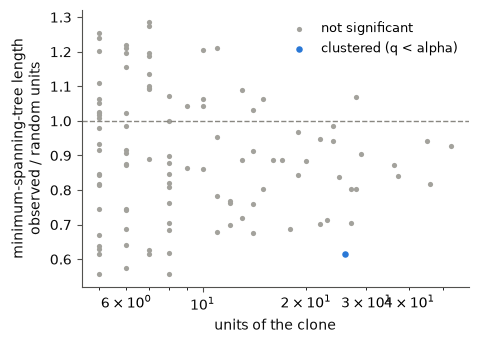

In [21]:
ax = pl.clone_dispersion(disp, measure="mst")
plt.show()

Most clones are more compact than random (ratios below 1), but none reaches q < 0.05 over the 106 clones tested (the
closest, clone 80, has q = 0.050 for the spanning-tree length). At day 21
the large clones have spread over several GCs and the plasma-cell area, so a single clone is rarely compact enough to
stand out on its own, even though clones *as a group* co-localise strongly (the trust report of this node, see
`02_is_my_data_spatial` for D14).

## Public clonotypes across six mice

The six AIR-SPACE nodes are six mice (Mock and days 3–21). MiXCR clone ids are per sample, so we first give every
record a clonotype id that is comparable between samples (`pp.define_clones(method="exact")`: chain + V gene + J gene +
junction amino acids) and then ask which clonotypes occur in at least two mice (`tl.public_clonotypes`). Light chains
are left out: their junctions are shared by unrelated cells too often to call sharing public.

In [22]:
nodes = ["Mock", "D3", "D7", "D10", "D14", "D21"]
tables = [spaclone.datasets.load_airspace(name, keep_x=False).air for name in nodes]
air6 = pp.filter_records(pd.concat(tables, ignore_index=True), on_tissue=True, loci=["IGH", "TRB"]).air
air6 = pp.define_clones(air6, method="exact", key_added="clonotype")
air6.groupby(["library_id", "locus"])["clonotype"].nunique().unstack().loc[nodes]

locus,IGH,TRB
library_id,,
Mock,354,612
D3,711,1390
D7,1012,433
D10,1854,909
D14,509,327
D21,840,383


In [23]:
pub = tl.public_clonotypes(air6, sample_key="library_id", clone_key="clonotype", unit="spot")
print(pub.groupby("locus")["public"].agg(["sum", "size"]))
pub[pub["public"]].head(10)[["clonotype", "n_samples", "samples", "n_units", "n_junction_nt"]]

       sum  size
locus           
IGH     12  5268
TRB     33  4017


,clonotype,n_samples,samples,n_units,n_junction_nt
0,TRB|TRBV16|TRBJ2-1|CASSLQGYAEQFF,4,D10;D14;D21;D7,9,5
1,TRB|TRBV13-3|TRBJ1-1|CASRGQGNTEVFF,3,D21;D3;D7,5,2
2,TRB|TRBV16|TRBJ2-4|CASSLEGSQNTLYF,3,D10;D14;D7,5,4
3,IGH|IGHV2-2|IGHJ4|CARSGAMDYW,2,D10;D14,30,4
4,IGH|IGHV1-64|IGHJ3|CAREGLLRGFAYW,2,D21;D7,15,3
5,TRB|TRBV16|TRBJ1-1|CASSLAANTEVFF,2,D10;D21,14,2
6,IGH|IGHV1-80|IGHJ2|CARGDYW,2,D10;D7,9,1
7,TRB|TRBV16|TRBJ2-7|CASSLELGGYEQYF,2,D10;D7,9,4
8,IGH|IGHV2-2|IGHJ1|CARNFDVW,2,D10;D14,7,1
9,IGH|IGHV3-8|IGHJ3|CARGGSWFAYW,2,D10;D21,7,2


45 clonotypes are found in two or more mice: 33 TRB and 12 IGH, out of more than 9,000. The most shared TRB chain
(CASSLQGYAEQFF, TRBV16, in four infected mice) is encoded by five different nucleotide junctions across the samples
(`n_junction_nt`): convergent recombination, the signature of a public chain made independently in each mouse rather
than of contamination between samples. `pgen=True` adds OLGA generation probabilities to test that further.

Are a mouse's *largest* clones more often public than its other clones? `tl.public_top_clones` compares the top 10
clones of each mouse with random sets of 10 of its clones:

In [24]:
ptc = tl.public_top_clones(air6[air6["locus"] == "IGH"], sample_key="library_id", clone_key="clonotype", rng=0)
ptc.table[["sample", "n_clones", "n_public", "statistic", "expected", "p_value"]]

,sample,n_clones,n_public,statistic,expected,p_value
0,D10,1854,6,0,0.032362,1.000000
1,D14,509,8,1,0.157171,0.142086
2,D21,840,7,0,0.083333,1.000000
3,D3,711,0,0,0.000000,1.000000
4,D7,1012,3,0,0.029644,1.000000
5,Mock,354,0,0,0.000000,1.000000
6,all,5280,24,1,0.302511,0.262674


No: one top-10 IGH clone out of 60 is public, against 0.3 expected (p = 0.26). The vaccinia response in these mice is
dominated by private heavy chains.

## A niche profile along the distance to the GC border

Where do T-cell receptor loci sit relative to germinal centres, compared with all receptor loci? `tl.signed_distance`
turns the GC mask into a distance map (negative inside), and `tl.niche_profile` gives, for each distance band, the
share of TCR loci divided by the share of all loci in that band, with pointwise intervals and a global envelope from
1,000 random labellings. With `blocks="clone_id"`, whole clones carry the TCR label in the null, so expanded T-cell
clones are not counted as independent units. The 0–20 µm band is kept separate: beads that close to a called border
are partly inside it.

In [25]:
in_tissue = G.obs["in_tissue"].to_numpy()
beads = pd.DataFrame({"x_um": G.obsm["spatial"][in_tissue, 0], "y_um": G.obsm["spatial"][in_tissue, 1]})
beads["region"] = G.obs_names[in_tissue].map(T.obs["region"].astype(str)).fillna("other")
grid = tl.Grid.from_points(beads["x_um"], beads["y_um"], pixel_um=10.0)
gc_mask = tl.tissue_mask(beads[beads["region"] == "GC"], grid=grid)
distance = tl.signed_distance(gc_mask)
loci, _ = tl.clone_units(air, unit="locus")
loci["tcr"] = loci["locus"].isin(["TRA", "TRB"])
loci["d_gc_um"] = distance.sample(loci["x_um"], loci["y_um"])
print(f"{len(loci):,} loci ({int(loci.tcr.sum())} TCR) | GC area {gc_mask.area_um2 / 1e6:.2f} mm²")
niche = tl.niche_profile(loci, group="tcr", distance_um="d_gc_um", bands_um=(-50, -20, 0, 20, 50, 100, 200, 400),
                         blocks="clone_id", n_perm=1000, rng=0)
print(niche)
niche.table[["label", "group_units", "baseline_units", "ratio", "ratio_lo", "ratio_hi", "p_value", "p_maxT"]].round(3)

12,318 loci (807 TCR) | GC area 0.35 mm²
TestResult(niche_profile: n_group=807, n_baseline=12318, n_pool=12318, bands=9, global_p=0.000999, most_extreme=[-50, -20); table 9×24)


,label,group_units,baseline_units,ratio,ratio_lo,ratio_hi,p_value,p_maxT
0,<-50,14,326,0.656,0.749,1.230,0.010,0.060
1,"[-50, -20)",15,489,0.468,0.802,1.207,0.002,0.001
2,"[-20, 0)",17,528,0.491,0.835,1.152,0.002,0.001
3,"[0, 20)",16,388,0.629,0.837,1.172,0.002,0.001
4,"[20, 50)",48,1007,0.728,0.873,1.125,0.002,0.001
5,"[50, 100)",60,1433,0.639,0.901,1.105,0.002,0.001
6,"[100, 200)",162,3082,0.802,0.942,1.066,0.002,0.001
7,"[200, 400)",295,3042,1.480,0.942,1.063,0.002,0.001
8,>=400,180,2023,1.358,0.906,1.087,0.002,0.001


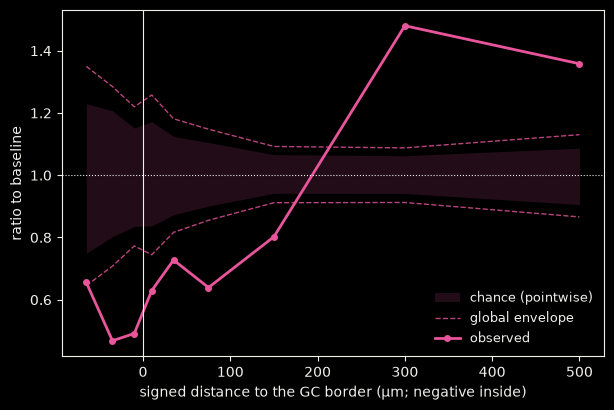

In [26]:
ax = pl.niche_profile(niche, receptor="TCR", xlabel="signed distance to the GC border (µm; negative inside)")
plt.show()

T-cell receptor loci avoid germinal centres and their surroundings. Inside GCs their share is about half of their
share among all receptor loci (ratios 0.47–0.49 from −50 to 0 µm), it stays below 1 up to 200 µm from the border,
and beyond 200 µm (the T zone and the medulla) T-cell loci are enriched 1.4–1.5 times. The global envelope rejects
"TCR loci follow all receptor loci" (global p = 0.001), and every band from −50 to 400 µm lies outside its pointwise
interval. The 0–20 µm band is read as the edge of the called border, not as outside.

## Summary

| Question | Function | D21 answer |
|---|---|---|
| Genes of germinal centres | `gex.rank_genes_regions` (pseudobulk, GCs as replicates) | GC programme up (Mki67, Pou2af1, ...), Ighd down |
| Cell classes that neighbour | `gex.nhood_enrichment` | GC B with plasma cells and B cells, T with stroma |
| Clonality by region | `tl.diversity` (rarefied + placebo) | plasma-cell area more clonal than random placement of intact clones; GCs within range |
| Clone sharing between regions | `tl.overlap` (placebo) | all regions share clones; the plasma-cell area more with the rest of the node than random placement |
| Single compact clones | `tl.clone_dispersion` | none after BH (clones span several GCs) |
| Public clonotypes | `tl.public_clonotypes` | 45 in ≥ 2 mice (33 TRB, convergent) |
| TCR loci and the GC border | `tl.niche_profile` | depleted in and around GCs (0.5×), enriched > 200 µm away (1.4×) |

**Caveats.** A 10 µm bead holds parts of one to a few cells, so cell types and regions are bead-level calls; the GC
border is drawn from GEX markers and carries a ~20 µm halo. Loci merge same-clone molecules within 15 µm, which can
join two neighbouring cells of one clone. The repertoire placebos (`"clones"`) move whole clones with their shape;
permuting clone labels or moving single units (`nulls.Permute`, `nulls.Relocate`) asks a different question (see
`05_custom_placebo`).

In [27]:
print(f"notebook run time: {time.time() - t_start:.0f} s")

notebook run time: 53 s
